#### Activity 

In [1]:
# !pip install torch seaborn pandas matplotlib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
import torch

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.7.1+cu118


In [4]:
np.random.seed(42)

X = np.linspace(-1, 1, 200)
y = X**2 + np.random.normal(0, 0.1, size=X.shape)

In [5]:
X_tensor = torch.tensor(X, dtype=torch.float32).reshape(-1, 1)
y_tensor = torch.tensor(y, dtype=torch.float32).reshape(-1, 1)

print(X_tensor.shape)
print(y_tensor.shape)

torch.Size([200, 1])
torch.Size([200, 1])


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

(torch.Size([160, 1]),
 torch.Size([40, 1]),
 torch.Size([160, 1]),
 torch.Size([40, 1]))

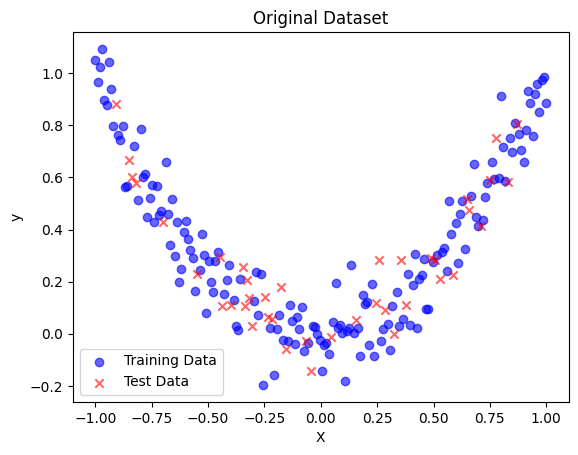

In [7]:
plt.scatter(X_train, y_train, color="blue", alpha=0.6, label="Training Data")
plt.scatter(X_test, y_test, color="red", marker="x", alpha=0.6, label="Test Data")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Original Dataset")
plt.legend()
plt.show()

In [8]:
import torch
import torch.nn as nn

class NeuralNetworkPytorch(nn.Module):

    def __init__(self, in_feature, hidden_feature, out_feature):
        super().__init__()

        self.linear_layer1 = nn.Linear(
            in_features=in_feature,
            out_features=hidden_feature
        )

        self.linear_layer2 = nn.Linear(
            in_features=hidden_feature,
            out_features=hidden_feature
        )

        self.linear_layer3 = nn.Linear(
            in_features=hidden_feature,
            out_features=out_feature
        )

        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.linear_layer1(x)
        x = self.relu(x)

        x = self.linear_layer2(x)
        x = self.relu(x)

        x = self.linear_layer3(x)

        return x

In [9]:
torch.manual_seed(42)

model = NeuralNetworkPytorch(
    in_feature=1,
    hidden_feature=16,
    out_feature=1
)

print(model)

NeuralNetworkPytorch(
  (linear_layer1): Linear(in_features=1, out_features=16, bias=True)
  (linear_layer2): Linear(in_features=16, out_features=16, bias=True)
  (linear_layer3): Linear(in_features=16, out_features=1, bias=True)
  (relu): ReLU()
)


In [10]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

In [11]:
epochs = 1000
loss_history = []

for epoch in range(epochs):

    # Forward propagation
    y_pred = model(X_train)

    # Calculate loss
    loss = criterion(y_pred, y_train)

    # Reset gradients
    optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update weights and biases
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch+1}, Loss: {loss.item():.6f}")

Epoch 100, Loss: 0.010776
Epoch 200, Loss: 0.009054
Epoch 300, Loss: 0.008922
Epoch 400, Loss: 0.008819
Epoch 500, Loss: 0.008725
Epoch 600, Loss: 0.008660
Epoch 700, Loss: 0.008610
Epoch 800, Loss: 0.008542
Epoch 900, Loss: 0.008257
Epoch 1000, Loss: 0.008117


In [12]:
# model.state_dict()

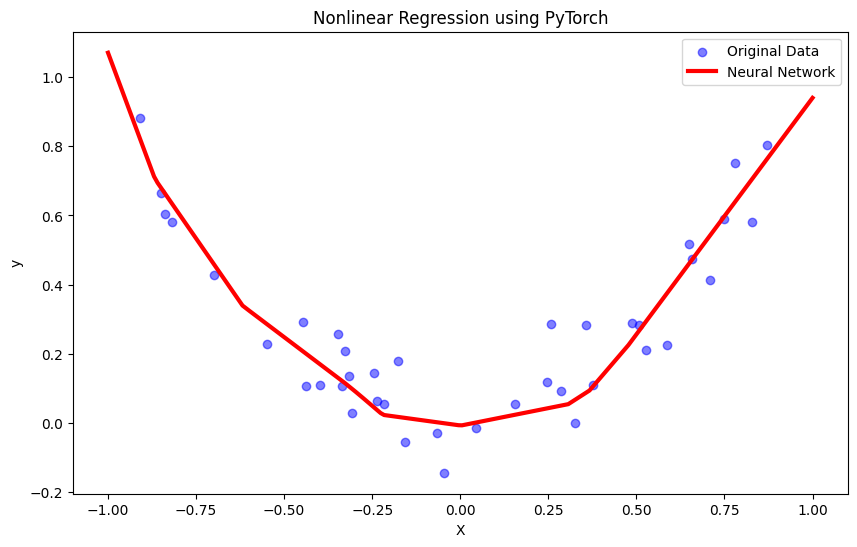

In [13]:
model.eval()

with torch.no_grad():
    predictions = model(X_tensor).numpy()

plt.figure(figsize=(10, 6))

plt.scatter(X_test, y_test, color="blue", alpha=0.5,
            label="Original Data")

plt.plot(X, predictions, color="red",
         linewidth=3, label="Neural Network")

# plt.plot(X, X**2, color="green",
#          linestyle="--", label="Actual Function")

plt.xlabel("X")
plt.ylabel("y")
plt.title("Nonlinear Regression using PyTorch")
plt.legend()
plt.show()

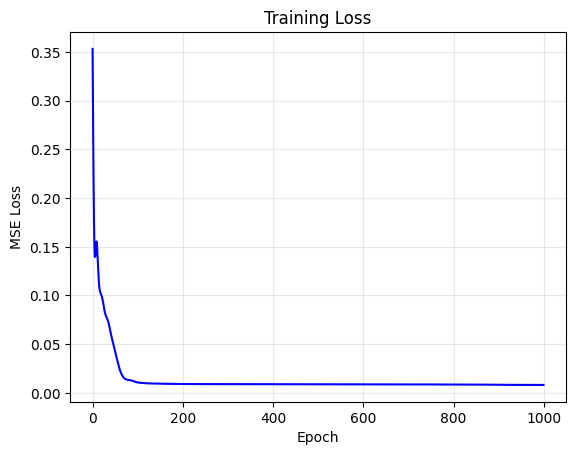

In [14]:
plt.plot(loss_history, color="blue")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.grid(alpha=0.3)
plt.show()

In [15]:
new_data = torch.tensor([
    [-0.8],
    [-0.5],
    [0.0],
    [0.5],
    [0.8]
], dtype=torch.float32)

with torch.no_grad():
    output = model(new_data)

print(output)

tensor([[ 0.6071],
        [ 0.2480],
        [-0.0075],
        [ 0.2560],
        [ 0.6665]])


In [16]:
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print(total_params)

321
